In [1]:
from lightgbm import LGBMRegressor
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_validate
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

train = pd.read_csv('train.csv')
y_log = np.log1p(train['SalePrice'])
digit = train.select_dtypes(include='number')
digit = digit.drop(columns=['Id','SalePrice'])

categorial = train.select_dtypes('str')
X_digit_features = digit
X_categorial_features = categorial

pipeline_digit_rf = make_pipeline(SimpleImputer(strategy='median'), RandomForestRegressor(n_estimators=200, random_state=42))
pipeline_digit_lgbm = make_pipeline(SimpleImputer(strategy='median'), LGBMRegressor(random_state=42, verbose=-1))
pipeline_categorial_rf = make_pipeline(SimpleImputer(strategy='constant', fill_value='None'),OneHotEncoder(handle_unknown='ignore'),RandomForestRegressor(n_estimators=200, random_state=42))
pipeline_categorial_lgbm = make_pipeline(SimpleImputer(strategy='constant', fill_value='None'),OneHotEncoder(handle_unknown='ignore'),LGBMRegressor(random_state=42, verbose=-1))

cross_val_digit_rf = cross_validate(pipeline_digit_rf,X_digit_features,y_log,cv = 5,scoring='neg_root_mean_squared_error')
cross_val_digit_lgbm = cross_validate(pipeline_digit_lgbm,X_digit_features,y_log,cv = 5 ,scoring='neg_root_mean_squared_error')
cross_val_categorial_rf = cross_validate(pipeline_categorial_rf,X_categorial_features,y_log,cv = 5 ,scoring='neg_root_mean_squared_error')
cross_val_categorial_lgbm = cross_validate(pipeline_categorial_lgbm,X_categorial_features,y_log,cv = 5 ,scoring='neg_root_mean_squared_error')
print('Случайный лес')
print('RMSE_digit:', -cross_val_digit_rf['test_score'].mean())
print('std_digit: ', cross_val_digit_rf['test_score'].std())
print('RMSE_categorial:', -cross_val_categorial_rf['test_score'].mean())
print('std_categorial: ', cross_val_categorial_rf['test_score'].std())
print()
print('LightGBM')
print('RMSE_digit:', -cross_val_digit_lgbm['test_score'].mean())
print('std_digit: ', cross_val_digit_lgbm['test_score'].std())
print('RMSE_categorial:', -cross_val_categorial_lgbm['test_score'].mean())
print('std_categorial: ', cross_val_categorial_lgbm['test_score'].std())



Случайный лес
RMSE_digit: 0.14677183035154723
std_digit:  0.009600420315043405
RMSE_categorial: 0.18814470674451816
std_categorial:  0.01807116513041923

LightGBM
RMSE_digit: 0.1375820774623727
std_digit:  0.007875342104997502
RMSE_categorial: 0.1823148561145624
std_categorial:  0.012562432236931825


In [2]:
# 1. списки столбцов (include='number' берёт и int, и float)

train['TotalSF'] = train['1stFlrSF'] + train['2ndFlrSF']+train['TotalBsmtSF']

train['HouseAge'] = train['YrSold'] - train['YearBuilt']

train['TotalBath'] = train['FullBath'] + train['HalfBath']*0.5 +train['BsmtFullBath']+train['BsmtHalfBath']*0.5

num_cols = train.select_dtypes(include='number').drop(columns=['Id', 'SalePrice']).columns
cat_cols = train.select_dtypes(exclude='number').columns

# 2. два маленьких пайплайна: по одному на группу столбцов
num_pipe = make_pipeline(SimpleImputer(strategy='median'))
cat_pipe = make_pipeline(
    SimpleImputer(strategy='constant', fill_value='None'),
    OneHotEncoder(handle_unknown='ignore'),
)

# 3. ColumnTransformer: (название, преобразователь, столбцы)
preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols),
])

# 4. один общий пайплайн: обработка + модель
model_rf = make_pipeline(preprocessor, RandomForestRegressor(n_estimators=200, random_state=42))
model_lgbm = make_pipeline(preprocessor, LGBMRegressor(random_state=42, verbose=-1))


# 5. X содержит ВСЕ признаки сразу
X = train.drop(columns=['Id', 'SalePrice'])

cv_rf = cross_validate(model_rf, X, y_log, cv=5, scoring='neg_root_mean_squared_error')
cv_lgbm = cross_validate(model_lgbm, X, y_log, cv=5, scoring='neg_root_mean_squared_error')

print('RF:  ', -cv_rf['test_score'].mean(), cv_rf['test_score'].std())
print('LGBM:', -cv_lgbm['test_score'].mean(), cv_lgbm['test_score'].std())

RF:   0.14245702061040003 0.009230913929798221
LGBM: 0.1308580745877494 0.008399572323653518


Получение новый столбцов не дало результатов(лишь в пределах шума)
для деревьев сложение столбцов не имело особого смысла так как они уже передаются туда

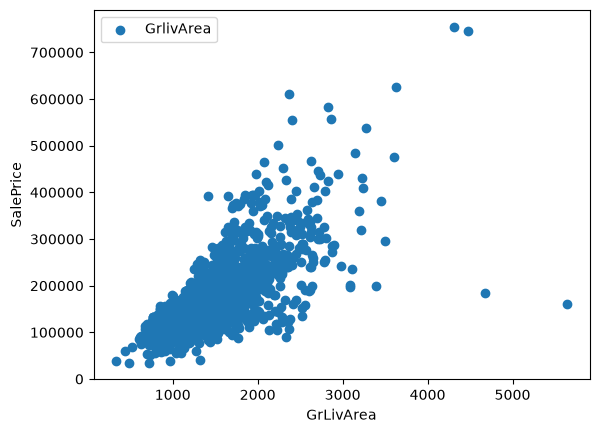

In [3]:
fig,ax = plt.subplots()
ax.scatter(train['GrLivArea'],train['SalePrice'],label = 'GrlivArea')
ax.legend()
ax.set_xlabel('GrLivArea')
ax.set_ylabel('SalePrice')
plt.show()



In [4]:
# 1. списки столбцов (include='number' берёт и int, и float)


num_cols = train.select_dtypes(include='number').drop(columns=['Id', 'SalePrice']).columns
cat_cols = train.select_dtypes(exclude='number').columns

# 2. два маленьких пайплайна: по одному на группу столбцов
num_pipe = make_pipeline(SimpleImputer(strategy='median'))
cat_pipe = make_pipeline(
    SimpleImputer(strategy='constant', fill_value='None'),
    OneHotEncoder(handle_unknown='ignore'),
)

# 3. ColumnTransformer: (название, преобразователь, столбцы)
preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols),
])

# 4. один общий пайплайн: обработка + модель
model_rf = make_pipeline(preprocessor, RandomForestRegressor(n_estimators=200, random_state=42))
model_lgbm = make_pipeline(preprocessor, LGBMRegressor(random_state=42, verbose=-1))


mask = (train['GrLivArea'] > 4000) & (train['SalePrice'] < 300000)
       # проверка: должно получиться 2

train_clean = train[~mask]
y_log_clean = np.log1p(train_clean['SalePrice'])
X_clean = train_clean.drop(columns=['Id', 'SalePrice'])

cv_rf = cross_validate(model_rf, X_clean, y_log_clean, cv=5, scoring='neg_root_mean_squared_error')
cv_lgbm = cross_validate(model_lgbm, X_clean, y_log_clean, cv=5, scoring='neg_root_mean_squared_error')

print('RF:  ', -cv_rf['test_score'].mean(), cv_rf['test_score'].std())
print('LGBM:', -cv_lgbm['test_score'].mean(), cv_lgbm['test_score'].std())

RF:   0.1362126243247392 0.004167628512379505
LGBM: 0.12663509962826452 0.005139982780228842


In [5]:
# копия, чтобы не было предупреждения SettingWithCopy
X_a = X_clean.copy()
X_a[['GarageYrBlt', 'MasVnrArea']] = X_a[['GarageYrBlt', 'MasVnrArea']].fillna(0)

print(X_a[num_cols].isna().sum()[lambda s: s > 0])   # должен остаться только LotFrontage

# вариант A: оставшиеся пропуски (LotFrontage) заполняет медиана
cv_a = cross_validate(model_lgbm, X_a, y_log_clean, cv=5,
                      scoring='neg_root_mean_squared_error')
print('A:', -cv_a['test_score'].mean(), cv_a['test_score'].std())

# вариант B: то же + столбец-флаг пропуска
num_pipe_b = make_pipeline(SimpleImputer(strategy='median', add_indicator=True))
preprocessor_b = ColumnTransformer([
    ('num', num_pipe_b, num_cols),
    ('cat', cat_pipe, cat_cols),
])
model_lgbm_b = make_pipeline(preprocessor_b, LGBMRegressor(random_state=42, verbose=-1))

cv_b = cross_validate(model_lgbm_b, X_a, y_log_clean, cv=5,
                      scoring='neg_root_mean_squared_error')
print('B:', -cv_b['test_score'].mean(), cv_b['test_score'].std())

LotFrontage    259
dtype: int64
A: 0.1271746380129784 0.00451257911587352
B: 0.12747594637383736 0.00444272535555376


In [7]:
test = pd.read_csv('test.csv')

test['TotalSF'] = test['1stFlrSF'] + test['2ndFlrSF']+test['TotalBsmtSF']

test['HouseAge'] = test['YrSold'] - test['YearBuilt']

test['TotalBath'] = test['FullBath'] + test['HalfBath']*0.5 +test['BsmtFullBath']+test['BsmtHalfBath']*0.5





X_test = test.drop(columns=['Id'])

model_fit = model_lgbm.fit(X_clean, y_log_clean)


pred_log = model_lgbm.predict(X_test)
pred = np.expm1(pred_log)

submission = pd.DataFrame({'Id': test['Id'], 'SalePrice': pred})
submission.to_csv('submission_w11.csv', index=False)
print(submission.head())

     Id      SalePrice
0  1461  121314.651730
1  1462  164296.250321
2  1463  180745.597423
3  1464  192146.260741
4  1465  185207.134483
